# **SmartFactory Predictive Maintenance and Visual Inspection**

This notebook compares Random Forest and a small feed-forward network on sensor data, then compares two CNN designs on casting images. The sensor and image models have different prediction targets, so their scores should not be treated as results on the same task.

# **Part A Classical and Feed Forward Models**

## **Sensor Data Preparation**


### **Upload the sensor dataset**

This cell uploads the AI4I CSV file from my computer to Colab. The uploaded file is used for the Random Forest and feed-forward network experiments.


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ai4i2020.csv to ai4i2020.csv


### **Load and preview the dataset**

This cell reads the CSV file into a pandas DataFrame. It shows the first five rows and the number of rows and columns so I can check that the data loaded correctly.


In [ ]:
import pandas as pd

df = pd.read_csv("ai4i2020.csv")

print(df.head())
print(df.shape)

   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0    0  
2    0  

### **Check the column names**

This cell lists all column names. This helps me identify the input measurements, product type, target column and columns that should be removed.


In [ ]:
print(df.columns)

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')


### **Check data types and available values**

This cell shows the data type and number of non-missing values in each column. It helps me check which columns contain numbers or text before preprocessing.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

### **Check for missing values**

This cell counts missing values in each column. The saved output shows no missing values, so missing-value replacement is not needed for this dataset.


In [ ]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


### **Choose the input features and target**

This cell uses Machine failure as the target and removes it from the inputs. It also removes the two identifier columns and the five failure-type flags. Removing those flags avoids giving the model information that directly describes the failure outcome.


In [ ]:
X = df.drop(['UDI', 'Product ID', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'], axis=1)
y = df['Machine failure']

### **Preview one-hot encoding for product type**

This cell converts product type into separate Type_H, Type_L and Type_M indicator columns and previews the result. This is a preview: the actual training and test inputs are encoded again later, after splitting.


In [ ]:
# Apply one-hot encoding to Type column
df_encoded = pd.get_dummies(X, columns=['Type'], drop_first=False)

# Display new columns
df_encoded.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,False,False,True
1,298.2,308.7,1408,46.3,3,False,True,False
2,298.1,308.5,1498,49.4,5,False,True,False
3,298.2,308.6,1433,39.5,7,False,True,False
4,298.2,308.7,1408,40.0,9,False,True,False


### **Split the data and scale the numerical inputs**

This cell keeps 70% of the rows for training and 30% for testing. Stratification keeps a similar share of failure cases in both sets. The scaler learns from the training partition only and then transforms both partitions, so the test data does not influence scaling.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Numerical columns for scaling
num_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

# Create scaler
scaler = StandardScaler()

# Fit only on training data, then transform train and test
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# Check result
X_train.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
1888,M,-1.105779,-1.759415,2.012835,-1.569298,0.334742
4858,L,1.840492,1.547973,-1.055557,1.099287,-0.041084
8990,L,-1.405400,-1.421926,-0.256554,-0.160045,0.600952
4901,M,1.790556,1.547973,0.503608,-0.759727,1.806727
7957,H,0.442262,1.277982,3.333409,-2.348885,-1.011967


## **Random Forest Modelling and Evaluation**


### **Train and evaluate Random Forest**

This cell encodes product type in both partitions and aligns the columns. It trains a Random Forest with 100 trees and balanced class weights, then evaluates it on the held-out test set. Failure precision, recall and F1 are reported alongside accuracy because failure cases are rare.


In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Dynamically apply one-hot encoding to training and testing sets
X_train_encoded = pd.get_dummies(X_train, columns=['Type'], drop_first=False)
X_test_encoded = pd.get_dummies(X_test, columns=['Type'], drop_first=False)

# Align columns to ensure both have the same one-hot features
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

# Train the model with encoded data
rf_model.fit(X_train_encoded, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test_encoded)

# Evaluate the model
print("Random Forest Results")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-score:", f1_score(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Results
Accuracy: 0.9773333333333334
Precision: 0.8695652173913043
Recall: 0.39215686274509803
F1-score: 0.5405405405405406

Confusion Matrix:
[[2892    6]
 [  62   40]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      2898
           1       0.87      0.39      0.54       102

    accuracy                           0.98      3000
   macro avg       0.92      0.70      0.76      3000
weighted avg       0.98      0.98      0.97      3000



### **Import the tools for Random Forest plots**

This cell imports the plotting tools and evaluation functions used in the following figures. These figures show classification errors, feature importance and performance across different decision thresholds.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score

### **Plot the Random Forest confusion matrix**

This heatmap compares actual and predicted labels. It separates correctly detected failures, missed failures, correctly identified normal cases and false alarms. This makes the practical errors easier to see than accuracy alone.


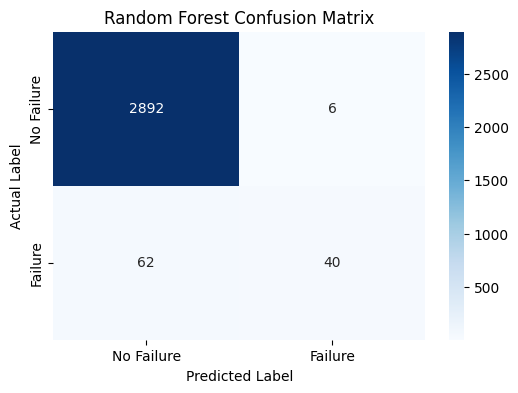

In [ ]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Failure', 'Failure'],
    yticklabels=['No Failure', 'Failure']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Random Forest Confusion Matrix')
plt.show()

### **Show the most important Random Forest inputs**

This plot ranks the inputs using the fitted forest's feature-importance scores. Higher scores mean the model relied more on those inputs when splitting its trees. These scores do not prove that an input causes machine failure.


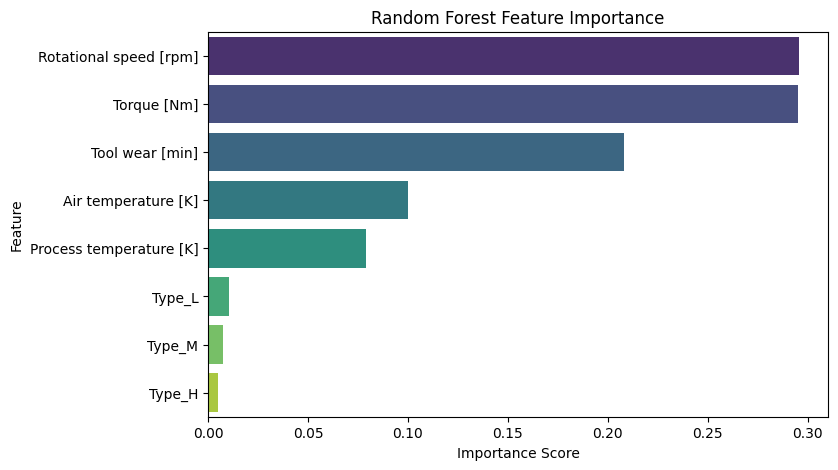

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a DataFrame using the encoded training columns
feature_importance = pd.DataFrame({
    'Feature': X_train_encoded.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance score
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

### **Plot the Random Forest ROC curve**

This cell plots failure detection against the false-positive rate across decision thresholds. ROC-AUC summarises how well the model ranks failure cases above normal cases. The precision-recall plot below gives additional information for this imbalanced dataset.


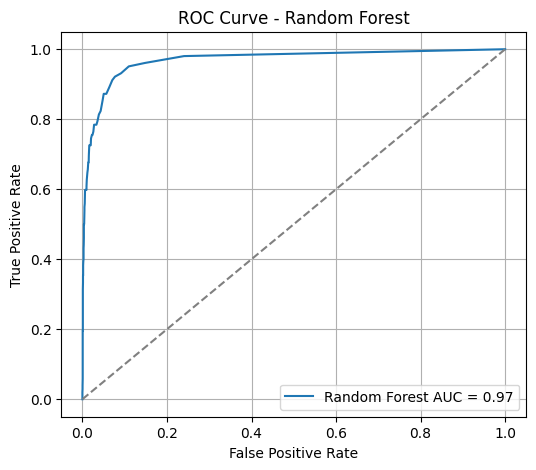

In [ ]:
y_proba_rf = rf_model.predict_proba(X_test_encoded)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_proba_rf)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Random Forest AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.grid(True)
plt.show()

### **Plot the Random Forest precision-recall curve**

This cell shows the trade-off between finding failures and keeping alerts reliable as the threshold changes. Average precision summarises the curve. This is useful because the failure class is much smaller than the normal class.


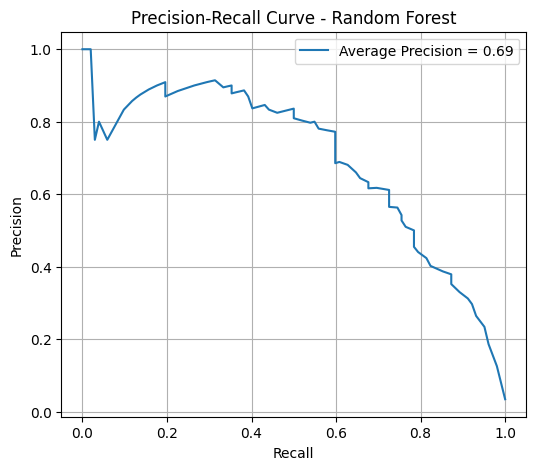

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba_rf)
avg_precision = average_precision_score(y_test, y_proba_rf)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f'Average Precision = {avg_precision:.2f}')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Random Forest')
plt.legend()
plt.grid(True)
plt.show()

# **Model Choice Justification**

Random Forest was selected as the classical machine learning model for this tabular sensor dataset. The dataset contains numerical manufacturing process variables such as air temperature, process temperature, rotational speed, torque, and tool wear, together with a categorical product type variable. Random Forest is suitable for this type of data because it can handle non-linear relationships between sensor readings and machine failure. It also combines many decision trees, which helps reduce overfitting compared with a single decision tree.
Another reason for choosing Random Forest is that the dataset is imbalanced, with many more normal cases than failure cases. Therefore, class_weight='balanced' was used so that the model gives more importance to the minority failure class. Random Forest also provides feature importance, which helps explain which variables contributed most to the prediction.

# **Evaluation**

The Random Forest model was evaluated using the same held-out test split as the neural network model will use later. Accuracy, precision, recall, F1-score, and the confusion matrix were used. Accuracy shows the overall percentage of correct predictions, but it is not enough for this dataset because the failure class is much smaller than the normal class. Therefore, precision, recall, and F1-score for the failure class are more important.
Based on the results, the model achieved high overall accuracy, meaning it correctly classified most samples. However, the recall for the failure class was lower, meaning some actual machine failures were missed. In a SmartFactory quality-control setting, this is important because missing a real failure could allow defective or risky production cases to continue. Therefore, the Random Forest model gives a strong baseline, but the failure-class recall should be improved before real deployment.

## **Feed Forward Network Modelling and Evaluation**


### **Import the tools for the feed-forward network**

This cell imports NumPy, TensorFlow and the layers, callbacks and evaluation tools needed for the small neural network. The network uses the same sensor features and held-out test rows as Random Forest.


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

### **Prepare numerical arrays for the neural network**

This cell converts the encoded inputs and target labels into float32 NumPy arrays for TensorFlow. It keeps the existing train-test split, allowing both sensor models to be tested on the same cases.


In [ ]:
# Convert one-hot encoded data into float format for TensorFlow
X_train_nn = np.asarray(X_train_encoded).astype('float32')
X_test_nn = np.asarray(X_test_encoded).astype('float32')

y_train_nn = np.asarray(y_train).astype('float32')
y_test_nn = np.asarray(y_test).astype('float32')

### **Calculate class weights for rare failures**

This cell calculates class weights from the training labels. Failure examples receive a larger weight because they are less common. This changes their contribution to training loss, but does not guarantee good failure recall or precision.


In [ ]:
classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

class_weight_dict

{np.int64(0): np.float64(0.5175218098477007),
 np.int64(1): np.float64(14.767932489451477)}

### **Build the small feed-forward network**

This network has hidden layers with 16 and eight units, followed by a sigmoid output for the failure score. It uses ReLU, 20% dropout, Adam and binary cross-entropy. The summary shows 289 trainable parameters, keeping the model small for the eight input columns.


In [ ]:
model = Sequential()

# Input + first hidden layer
model.add(Dense(16, activation='relu', input_shape=(X_train_nn.shape[1],)))

# Second hidden layer
model.add(Dense(8, activation='relu'))

# Dropout to reduce overfitting
model.add(Dropout(0.2))

# Output layer for binary classification
model.add(Dense(1, activation='sigmoid'))

# Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

### **Train the network with early stopping**

This cell trains for up to 50 epochs using batches of 32. It reserves 20% of the training partition for validation and applies the class weights. Early stopping checks validation loss and restores the best weights if training ends without further improvement.


In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_nn,
    y_train_nn,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.2686 - loss: 0.6722 - val_accuracy: 0.4236 - val_loss: 0.7370
Epoch 2/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5664 - loss: 0.5691 - val_accuracy: 0.6886 - val_loss: 0.6427
Epoch 3/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7596 - loss: 0.5018 - val_accuracy: 0.7943 - val_loss: 0.5444
Epoch 4/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7954 - loss: 0.4491 - val_accuracy: 0.8471 - val_loss: 0.4440
Epoch 5/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8336 - loss: 0.4178 - val_accuracy: 0.8371 - val_loss: 0.4358
Epoch 6/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8323 - loss: 0.3884 - val_accuracy: 0.8743 - val_loss: 0.3561
Epoch 7/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8584 - loss: 0.3696 - val_accuracy: 0.8657 - val_loss: 0.3476
Epoch 8/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8516 - loss: 0.3607 - val_accuracy: 0.

### **Evaluate the network on the same test set**

This cell predicts failure scores and uses a threshold of 0.5 to assign labels. It reports accuracy, failure precision, recall, F1 and a confusion matrix. These results can be compared directly with Random Forest because the test cases are the same.


In [ ]:
# Predict probabilities
y_pred_prob_nn = model.predict(X_test_nn)

# Convert probabilities to class labels
y_pred_nn = (y_pred_prob_nn >= 0.5).astype(int)

print("Neural Network Results")
print("Accuracy:", accuracy_score(y_test_nn, y_pred_nn))
print("Precision:", precision_score(y_test_nn, y_pred_nn))
print("Recall:", recall_score(y_test_nn, y_pred_nn))
print("F1-score:", f1_score(y_test_nn, y_pred_nn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_nn, y_pred_nn))

print("\nClassification Report:")
print(classification_report(y_test_nn, y_pred_nn))

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Neural Network Results
Accuracy: 0.8916666666666667
Precision: 0.21628498727735368
Recall: 0.8333333333333334
F1-score: 0.3434343434343434

Confusion Matrix:
[[2590  308]
 [  17   85]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      0.89      0.94      2898
         1.0       0.22      0.83      0.34       102

    accuracy                           0.89      3000
   macro avg       0.60      0.86      0.64      3000
weighted avg       0.97      0.89      0.92      3000



A simple feed-forward neural network was developed as the mandatory neural network model. The model contains two hidden Dense layers using ReLU activation and one output layer using sigmoid activation because the task is binary classification. The model was trained using the Adam optimizer and binary cross-entropy loss. Class weights were applied because the dataset is imbalanced, with fewer machine failure cases than normal cases. Early stopping was used to reduce overfitting by stopping training when validation loss stopped improving.

### **Import the tools for neural network plots**

This cell imports the plotting and metric functions used to inspect the network's training behaviour and test performance. The next cells display learning curves, classification errors and threshold-based evaluation plots.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score

### **Plot training and validation accuracy**

This graph shows how training and validation accuracy change across epochs. It helps me check whether learning improves and whether the two curves begin to separate. Since failures are rare, these curves should be considered alongside failure recall and precision.


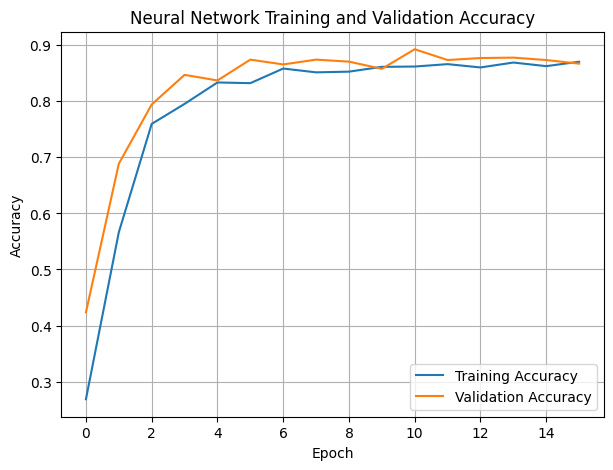

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Neural Network Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

### **Plot training and validation loss**

This graph checks whether validation loss improves as training continues. Falling training loss with worsening validation loss can suggest overfitting. Training loss uses class weights and dropout, while validation loss does not, so their absolute values are not directly equivalent.


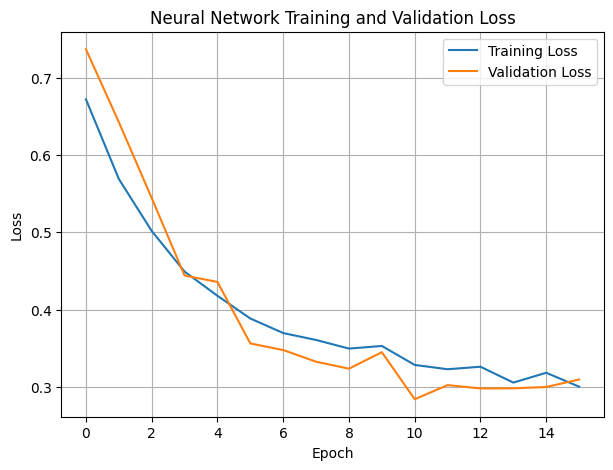

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Neural Network Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### **Plot the neural network confusion matrix**

This heatmap shows how many failure and normal cases the network classifies correctly or incorrectly. Comparing it with the forest's matrix shows the trade-off between missed failures and false alarms.


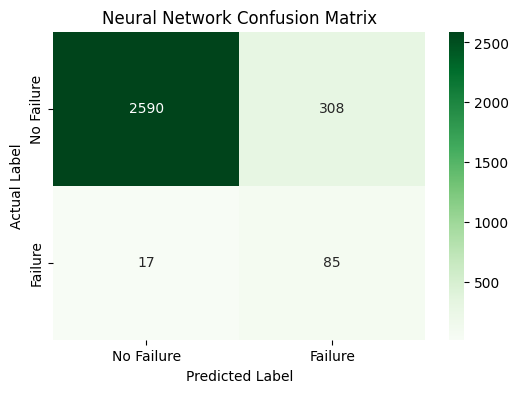

In [ ]:
cm_nn = confusion_matrix(y_test_nn, y_pred_nn)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nn,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Failure', 'Failure'],
    yticklabels=['No Failure', 'Failure']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Neural Network Confusion Matrix')
plt.show()

### **Plot the neural network ROC curve**

This cell plots the network's failure detection against its false-positive rate across thresholds. ROC-AUC summarises its ranking performance. The same type of plot was used for Random Forest, providing another way to compare the sensor models.


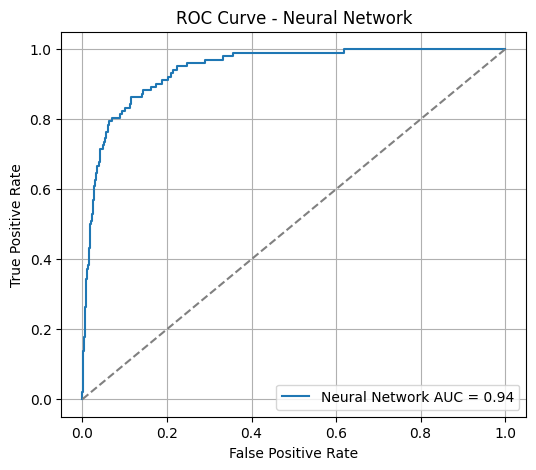

In [ ]:
fpr_nn, tpr_nn, thresholds_nn = roc_curve(y_test_nn, y_pred_prob_nn)
roc_auc_nn = auc(fpr_nn, tpr_nn)

plt.figure(figsize=(6, 5))
plt.plot(fpr_nn, tpr_nn, label=f'Neural Network AUC = {roc_auc_nn:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Neural Network')
plt.legend()
plt.grid(True)
plt.show()

### **Plot the neural network precision-recall curve**

This graph shows how failure precision and recall change across thresholds. Average precision summarises this trade-off. Comparing it with the forest's curve helps me judge which model ranks likely failures more effectively.


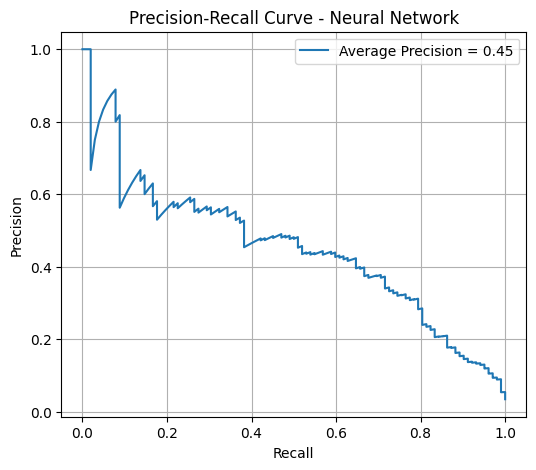

In [ ]:
precision_nn, recall_nn, thresholds_pr_nn = precision_recall_curve(y_test_nn, y_pred_prob_nn)
avg_precision_nn = average_precision_score(y_test_nn, y_pred_prob_nn)

plt.figure(figsize=(6, 5))
plt.plot(recall_nn, precision_nn, label=f'Average Precision = {avg_precision_nn:.2f}')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Neural Network')
plt.legend()
plt.grid(True)
plt.show()

# **Model Choice Justification**

A simple feed-forward neural network was selected as the mandatory neural network model for the tabular sensor dataset. The dataset contains numerical process measurements such as temperature, rotational speed, torque, and tool wear, which can be used as input features for a multi-layer perceptron. The MLP is suitable because it can learn non-linear relationships between sensor readings and machine failure through hidden layers and backpropagation.
The model was kept small because the dataset is tabular and not very complex. A very deep neural network may overfit, especially because the failure class is much smaller than the normal class. Therefore, the network used a small number of dense layers, ReLU activation in the hidden layers, and a sigmoid output layer for binary classification. Class weights were also applied to reduce the effect of class imbalance.

# **Evaluation**

The neural network was evaluated using the same held-out test split used for the Random Forest model. This makes the comparison fair because both models were tested on the same unseen data. The evaluation metrics used were accuracy, precision, recall, F1-score, and confusion matrix.
Accuracy measures the overall number of correct predictions, but it is not enough for this dataset because the classes are imbalanced. Therefore, precision, recall, and F1-score for the failure class are more important. In a SmartFactory setting, recall is especially important because missing an actual machine failure can be costly.

# **Part B Convolutional Neural Networks**

The image experiment compares CNN V1 and CNN V2 using separate training, validation and test sets. Both models are trained from scratch.


### **Upload and extract the casting image dataset**

This cell uploads one dataset ZIP file and extracts it into a Colab folder. It checks that exactly one ZIP was selected before extraction. The extracted images are used for the CNN experiments.


In [ ]:
from google.colab import files
from pathlib import Path
import zipfile

uploaded = files.upload()  # Select your downloaded dataset ZIP

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if len(zip_files) != 1:
    raise ValueError("Please upload exactly one dataset ZIP file.")

dataset_path = Path("/content/casting_dataset")

with zipfile.ZipFile(zip_files[0], "r") as archive:
    archive.extractall(dataset_path)

print("Dataset extracted to:", dataset_path)

Saving archive (8).zip to archive (8).zip
Dataset extracted to: /content/casting_dataset


### **Find the image folders and count each class**

This cell finds the original casting_512x512 folder containing the OK and defective subfolders. It counts the JPEG images in each class so I can check the dataset location and class sizes before splitting.


In [ ]:
candidates = [
    p for p in dataset_path.rglob("casting_512x512")
    if (p / "ok_front").is_dir()
    and (p / "def_front").is_dir()
]

if not candidates:
    raise FileNotFoundError(
        "The original casting_512x512 folder was not found."
    )

image_dir = candidates[0]

print("Image folder:", image_dir)
print("OK images:", len(list((image_dir / "ok_front").glob("*.jpeg"))))
print("Defective images:", len(list((image_dir / "def_front").glob("*.jpeg"))))

Image folder: /content/casting_dataset/casting_512x512/casting_512x512
OK images: 519
Defective images: 781


### **Label and split the casting images**

This cell labels OK images as 0 and defective images as 1, then creates stratified training, validation and test sets using a fixed seed. The split is 70%, 15% and 15%. Validation is used to choose the CNN design; the test set is kept for the selected model's final evaluation.


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

SEED = 42
tf.keras.utils.set_random_seed(SEED)

class_names = ["OK", "Defective"]
folder_labels = {"ok_front": 0, "def_front": 1}

paths, labels = [], []

for folder, label in folder_labels.items():
    for file in sorted((image_dir / folder).rglob("*")):
        if file.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            paths.append(str(file))
            labels.append(label)

paths = np.asarray(paths)
labels = np.asarray(labels, dtype=np.int32)

train_paths, remaining_paths, train_labels, remaining_labels = (
    train_test_split(
        paths,
        labels,
        test_size=0.30,
        stratify=labels,
        random_state=SEED
    )
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    remaining_paths,
    remaining_labels,
    test_size=0.50,
    stratify=remaining_labels,
    random_state=SEED
)

counts = pd.DataFrame({
    "Training": np.bincount(train_labels, minlength=2),
    "Validation": np.bincount(val_labels, minlength=2),
    "Testing": np.bincount(test_labels, minlength=2)
}, index=class_names)

display(counts)

,Training,Validation,Testing
OK,363,78,78
Defective,547,117,117


### **Build the image-loading pipeline**

This cell reads the images in grayscale, resizes them to 128 by 128 and groups them into batches of 32. It shuffles the training data and uses parallel loading and prefetching to help supply batches efficiently. Pixel rescaling is performed inside the CNN in a later cell.


In [ ]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )
    image.set_shape([None, None, 1])
    image = tf.image.resize(image, IMAGE_SIZE)

    label = tf.reshape(tf.cast(label, tf.float32), [1])
    return image, label

def make_dataset(image_paths, image_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (image_paths, image_labels)
    )

    if training:
        ds = ds.shuffle(
            len(image_paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

### **Preview the training images and labels**

This cell displays up to eight training images with their class labels. It helps me check that the images load correctly, the labels match their folders and the grayscale appearance is suitable before training.


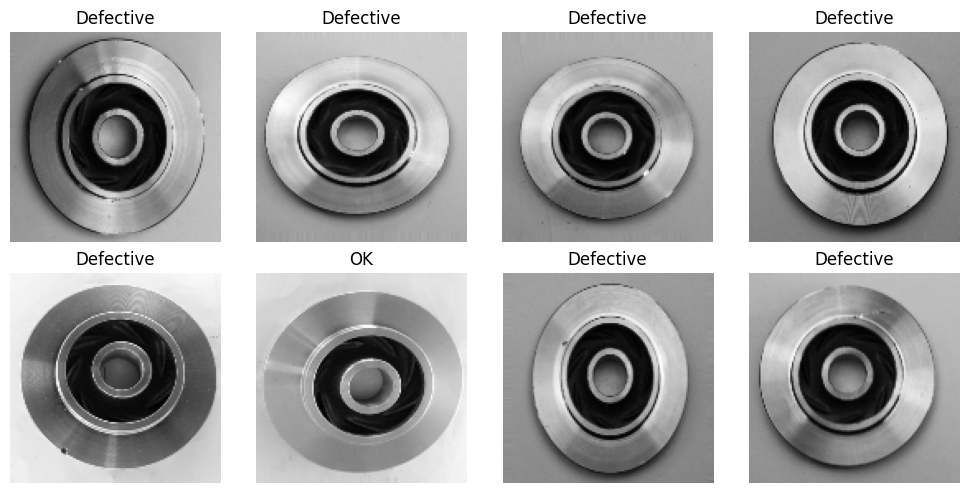

In [ ]:
preview_ds = make_dataset(train_paths, train_labels)

images, batch_labels = next(iter(preview_ds))

plt.figure(figsize=(10, 5))

for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().squeeze(), cmap="gray")
    plt.title(class_names[int(batch_labels[i, 0].numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

### **Define a CNN that can use different filter settings**

This function creates a new CNN from scratch for each filter list. It rescales pixels, applies small random rotations during training, and adds convolution and max-pooling blocks. A dense layer, 30% dropout and sigmoid output complete the model. Adam and binary cross-entropy are used for training.


In [ ]:
from tensorflow.keras import Sequential, layers

def build_cnn(filters, name):
    model = Sequential([
        layers.Input(shape=(*IMAGE_SIZE, 1)),
        layers.Rescaling(1.0 / 255),

        # Small rotations; inspect whether these preserve visible defects.
        layers.RandomRotation(0.03, seed=SEED)
    ], name=name)

    for number_of_filters in filters:
        model.add(layers.Conv2D(
            number_of_filters,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ))
        model.add(layers.MaxPooling2D(pool_size=(2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(32, activation="relu"))
    model.add(layers.Dropout(0.30))
    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

### **Train CNN V1 and V2 and compare validation results**

This cell trains V1 with 16 and 32 filters and V2 with 16, 32 and 64 filters. Both use the same image split and training settings, with up to 30 epochs and early stopping. The table compares parameter counts, validation loss, accuracy and defect F1 without using test results to choose the design.


In [ ]:
from sklearn.metrics import f1_score
from tensorflow.keras.callbacks import EarlyStopping

architectures = {
    "CNN_V1": [16, 32],
    "CNN_V2": [16, 32, 64]
}

cnn_models = {}
cnn_histories = {}
validation_results = []

for name, filters in architectures.items():
    tf.keras.utils.set_random_seed(SEED)

    train_ds = make_dataset(
        train_paths, train_labels, training=True
    )

    cnn = build_cnn(filters, name)
    cnn.summary()

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = cnn.fit(
        train_ds,
        validation_data=val_ds,
        epochs=30,
        callbacks=[early_stop],
        verbose=1
    )

    val_probabilities = cnn.predict(
        val_ds, verbose=0
    ).ravel()

    val_predictions = (
        val_probabilities >= 0.5
    ).astype(int)

    val_metrics = cnn.evaluate(
        val_ds,
        return_dict=True,
        verbose=0
    )

    cnn_models[name] = cnn
    cnn_histories[name] = history

    validation_results.append({
        "Model": name,
        "Parameters": cnn.count_params(),
        "Validation loss": val_metrics["loss"],
        "Validation accuracy": val_metrics["accuracy"],
        "Validation defect F1": f1_score(
            val_labels,
            val_predictions,
            zero_division=0
        )
    })

validation_comparison = pd.DataFrame(validation_results)
display(validation_comparison)

Model: "CNN_V1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │     1,048,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,053,441 (4.02 MB)

 Trainable params: 1,053,441 (4.02 MB)

 Non-trainable params: 0 (0.00 B)

...

 Total params: 547,649 (2.09 MB)

 Trainable params: 547,649 (2.09 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.6275 - loss: 0.6469 - val_accuracy: 0.6308 - val_loss: 0.6040
Epoch 2/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.7143 - loss: 0.5746 - val_accuracy: 0.7128 - val_loss: 0.5939
Epoch 3/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7363 - loss: 0.5401 - val_accuracy: 0.7487 - val_loss: 0.5244
Epoch 4/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.7582 - loss: 0.5198 - val_accuracy: 0.7590 - val_loss: 0.4992
Epoch 5/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7549 - loss: 0.5060 - val_accuracy: 0.8000 - val_loss: 0.4770
Epoch 6/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.7769 - loss: 0.4525 - val_accuracy: 0.7128 - val_loss: 0.5183
Epoch 7/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.7868 - loss: 0.4090 - val_accuracy: 0.7744 - val_loss: 0.4619
Epoch 8/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.8044 - loss: 0.3752 - val_accuracy: 0.8000 - v

,Model,Parameters,Validation loss,Validation accuracy,Validation defect F1
0,CNN_V1,1053441,0.238925,0.897436,0.913793
1,CNN_V2,547649,0.110816,0.948718,0.957265


### **Compare the CNN learning curves**

These graphs show training and validation loss and accuracy for both CNN versions. They help me compare learning progress, gaps between training and validation, and unstable validation results. This evidence supports the architecture choice alongside the validation metrics.


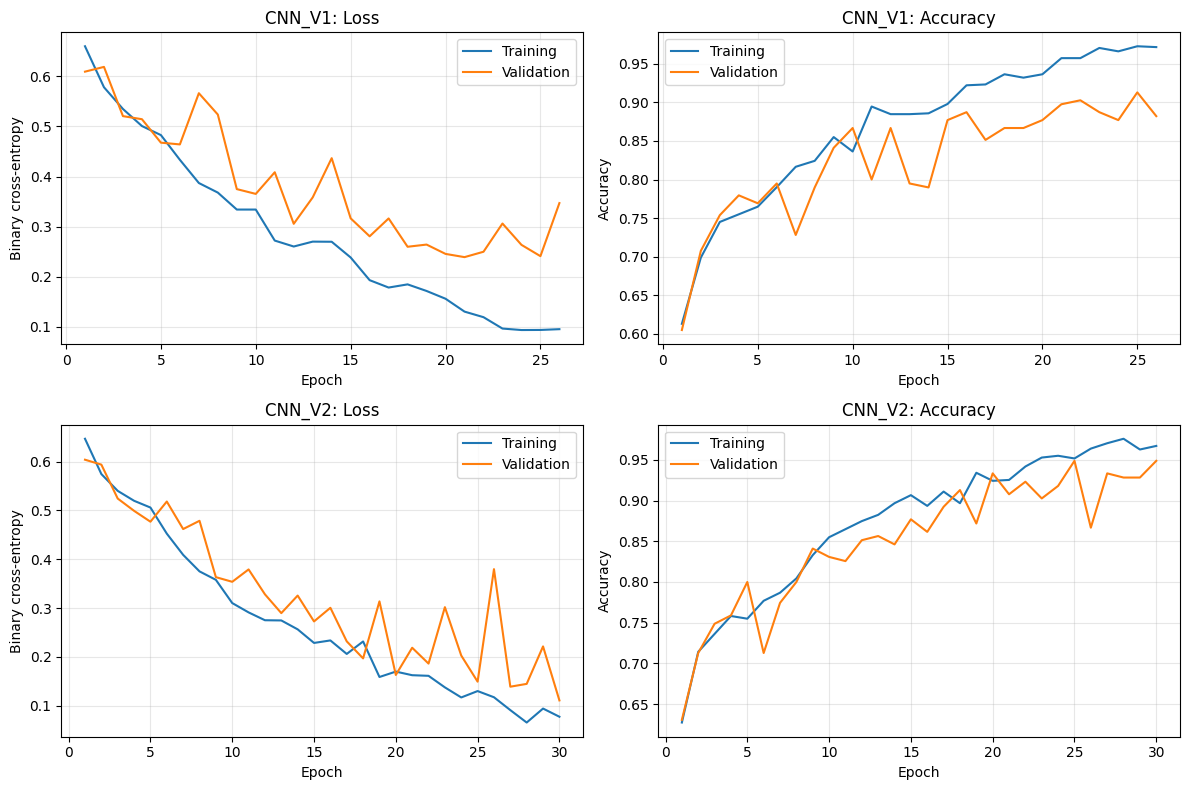

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (name, history) in enumerate(cnn_histories.items()):
    epochs = range(1, len(history.history["loss"]) + 1)

    axes[row, 0].plot(
        epochs, history.history["loss"], label="Training"
    )
    axes[row, 0].plot(
        epochs, history.history["val_loss"], label="Validation"
    )
    axes[row, 0].set_title(f"{name}: Loss")
    axes[row, 0].set_ylabel("Binary cross-entropy")

    axes[row, 1].plot(
        epochs, history.history["accuracy"], label="Training"
    )
    axes[row, 1].plot(
        epochs, history.history["val_accuracy"],
        label="Validation"
    )
    axes[row, 1].set_title(f"{name}: Accuracy")
    axes[row, 1].set_ylabel("Accuracy")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### **Select the CNN using validation data and test it**

This cell selects the highest validation defect F1, using lower validation loss to break a tie. It then evaluates that selected model on the held-out image test set at a threshold of 0.5. Accuracy, balanced accuracy, defect precision, recall, F1, ROC-AUC and average precision describe different aspects of its performance.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

ranked_models = validation_comparison.sort_values(
    ["Validation defect F1", "Validation loss"],
    ascending=[False, True]
)

best_name = ranked_models.iloc[0]["Model"]
cnn_model = cnn_models[best_name]

print("Selected architecture:", best_name)

y_prob_cnn = cnn_model.predict(
    test_ds, verbose=0
).ravel()

y_pred_cnn = (y_prob_cnn >= 0.5).astype(int)

test_results = pd.Series({
    "Accuracy": accuracy_score(test_labels, y_pred_cnn),
    "Balanced accuracy": balanced_accuracy_score(
        test_labels, y_pred_cnn
    ),
    "Defect precision": precision_score(
        test_labels, y_pred_cnn, zero_division=0
    ),
    "Defect recall": recall_score(
        test_labels, y_pred_cnn, zero_division=0
    ),
    "Defect F1": f1_score(
        test_labels, y_pred_cnn, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(test_labels, y_prob_cnn),
    "Average precision": average_precision_score(
        test_labels, y_prob_cnn
    )
})

display(test_results.round(4))

print(classification_report(
    test_labels,
    y_pred_cnn,
    target_names=class_names,
    digits=4,
    zero_division=0
))

Selected architecture: CNN_V2


,0
Accuracy,0.9641
Balanced accuracy,0.9658
Defect precision,0.9825
Defect recall,0.9573
Defect F1,0.9697
ROC-AUC,0.9906
Average precision,0.9945


              precision    recall  f1-score   support

          OK     0.9383    0.9744    0.9560        78
   Defective     0.9825    0.9573    0.9697       117

    accuracy                         0.9641       195
   macro avg     0.9604    0.9658    0.9628       195
weighted avg     0.9648    0.9641    0.9642       195

